# Tarea 3 — Aprendizaje no supervisado

## Identificación de perfiles de estudiantes mediante clustering jerárquico

**Objetivo:** descubrir si existen grupos naturales de estudiantes con trayectorias diferenciadas, partiendo del conjunto completo de variables (excluyendo solo la propia variable `objetivo`, que se usará a posteriori para validar los perfiles encontrados).

### Decisiones metodológicas

| Decisión | Elección | Justificación |
|---|---|---|
| Subconjunto de variables | Todas excepto `objetivo` | Perfiles completos. La variable `objetivo` se reserva para validar. |
| Linkage | Ward + Average + Complete | Ward suele dar dendrogramas más legibles e interpretables. Los otros dos sirven de control. |
| Métrica de distancia | Euclídea | Obligatoria para Ward |
| Reducción de dimensión | PCA al 90% de varianza | Tras OneHot tenemos ~100 dimensiones. La distancia pierde sentido (curse of dimensionality). |
| Elección de k | Mayor salto en las distancias de fusión del dendrograma | Heurística visual e interpretable, equivalente al "codo" aplicado al merging-distance vector. |
| Validación | Silhouette + tabla de contingencia con `objetivo`| Comprobar el resultado por varias vías. |


## 1. Imports y configuración

In [2]:
import sys
from pathlib import Path

# Hacemos accesible el módulo src/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from unsupervised import (
    cargar_datos_clustering,
    construir_matriz_features,
    calcular_linkages,
    plot_dendrograma,
    seleccionar_k_por_gap,
    plot_saltos,
    ajustar_clusters,
    evaluar_silueta,
    perfilar_clusters,
    plot_heatmap_perfiles)

from configuracion import CLASIFICACION_TRAIN, CLASIFICACION_TEST

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

## 2. Carga de datos

Unimos train + test porque el clustering es no supervisado: usar todo el dataset aumenta el N efectivo y la estabilidad de los grupos. La columna `objetivo` se conserva pero se separa de la matriz de features.

In [3]:
df = cargar_datos_clustering(
    path_train=CLASIFICACION_TRAIN,
    path_test=CLASIFICACION_TEST)

df.head()

Dataset cargado para clustering: 4349 filas x 36 columnas
Distribución de 'objetivo':
objetivo
2    2162
0    1401
1     786


,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,cualificacion_madre,cualificacion_padre,ocupacion_madre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,acceso_ordinario,1,turismo,diurna,secundaria,119.0,educacion_secundaria_12o_ano_o_equivalente,educacion_secundaria_12o_ano_o_equivalente,personal_administrativo,...,0,6,6,2,10.500,0,10.8,1.4,1.74,1
1,soltero/a,acceso_ordinario,2,animacion_y_diseno_multimedia,diurna,secundaria,141.0,educacion_basica_3er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,trabajadoras_no_cualificadas,...,0,0,0,0,0.000,0,12.7,3.7,-1.70,1
2,soltero/a,acceso_ordinario,2,servicio_social_nocturno,vespertina,secundaria,96.0,educacion_superior_grado,educacion_secundaria_12o_ano_o_equivalente,tecnicos_y_profesiones_de_nivel_intermedio,...,0,6,6,4,11.250,0,9.4,-0.8,-3.12,1
3,soltero/a,acceso_ordinario,1,enfermeria_veterinaria,diurna,secundaria,130.0,educacion_basica_3er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,trabajadoras_no_cualificadas,...,0,6,6,6,12.875,0,11.1,0.6,2.02,2
4,casado/a,movilidad_academica,1,gestion,diurna,secundaria,133.1,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,trabajadoras_no_cualificadas,...,0,5,5,0,0.000,0,10.8,1.4,1.74,0


## 3. Construcción de la matriz de features

1. Excluir `objetivo`.
2. Numéricas -> `StandardScaler` (z-score).
3. Categóricas -> `OneHotEncoder(drop='first')`
4. PCA al 90% de varianza.

**Nota:** sin PCA, tendríamos ~100 dimensiones (dummies de `curso`, `ocupacion_*`, `cualificacion_*`). En este espacio, las distancias euclídeas tienden a igualarse y los clusters pierden contraste. PCA al 90% reduce a 30 componentes manteniendo casi toda la información.

In [4]:
X, nombres_features, preprocesador, pca = construir_matriz_features(
    df,
    excluir_cols=["objetivo"],
    aplicar_pca=True,
    varianza_pca=0.90)

print(f"\nForma final de la matriz: {X.shape}")
print(f"Reducción: {len(nombres_features)} -> {X.shape[1]} dimensiones "
      f"({100*X.shape[1]/len(nombres_features):.0f}%)")

Matriz tras preprocesado: 4349 x 99 dimensiones
  - Numéricas (escaladas):  19
  - Categóricas (OneHot):   80
PCA: 30 componentes para conservar el 90% de la varianza

Forma final de la matriz: (4349, 30)
Reducción: 99 -> 30 dimensiones (30%)


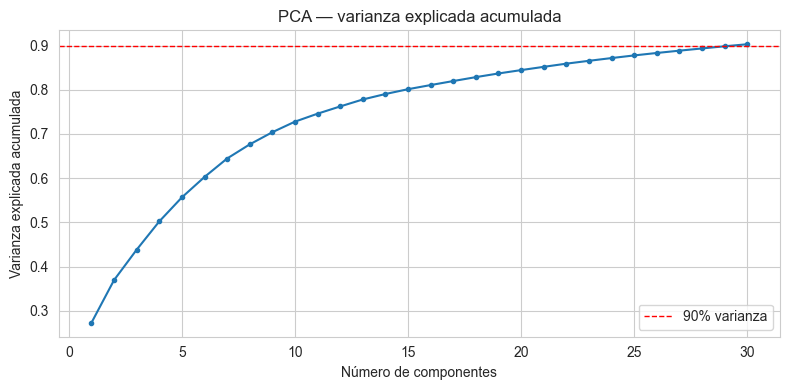

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
var_acum = np.cumsum(pca.explained_variance_ratio_)
ax.plot(range(1, len(var_acum) + 1), var_acum, marker="o", markersize=3)
ax.axhline(0.90, color="red", linestyle="--", linewidth=1, label="90% varianza")
ax.set_xlabel("Número de componentes")
ax.set_ylabel("Varianza explicada acumulada")
ax.set_title("PCA — varianza explicada acumulada")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Cálculo de matrices de linkage

Calculamos los tres métodos:
- **Ward:** minimiza la varianza intra-cluster en cada fusión.
- **Average:** distancia media entre todos los pares de puntos de los dos clusters. Más robusto a outliers.
- **Complete:** distancia entre los puntos más lejanos.

In [6]:
linkages = calcular_linkages(X, metodos=("ward", "average", "complete"))

Linkage 'ward': matriz de fusiones (4348, 4) calculada
Linkage 'average': matriz de fusiones (4348, 4) calculada
Linkage 'complete': matriz de fusiones (4348, 4) calculada


## 5. Dendrogramas comparativos

Mostramos los tres dendrogramas truncados a las últimas 30 fusiones (con N=4349, el dendrograma completo es ilegible).

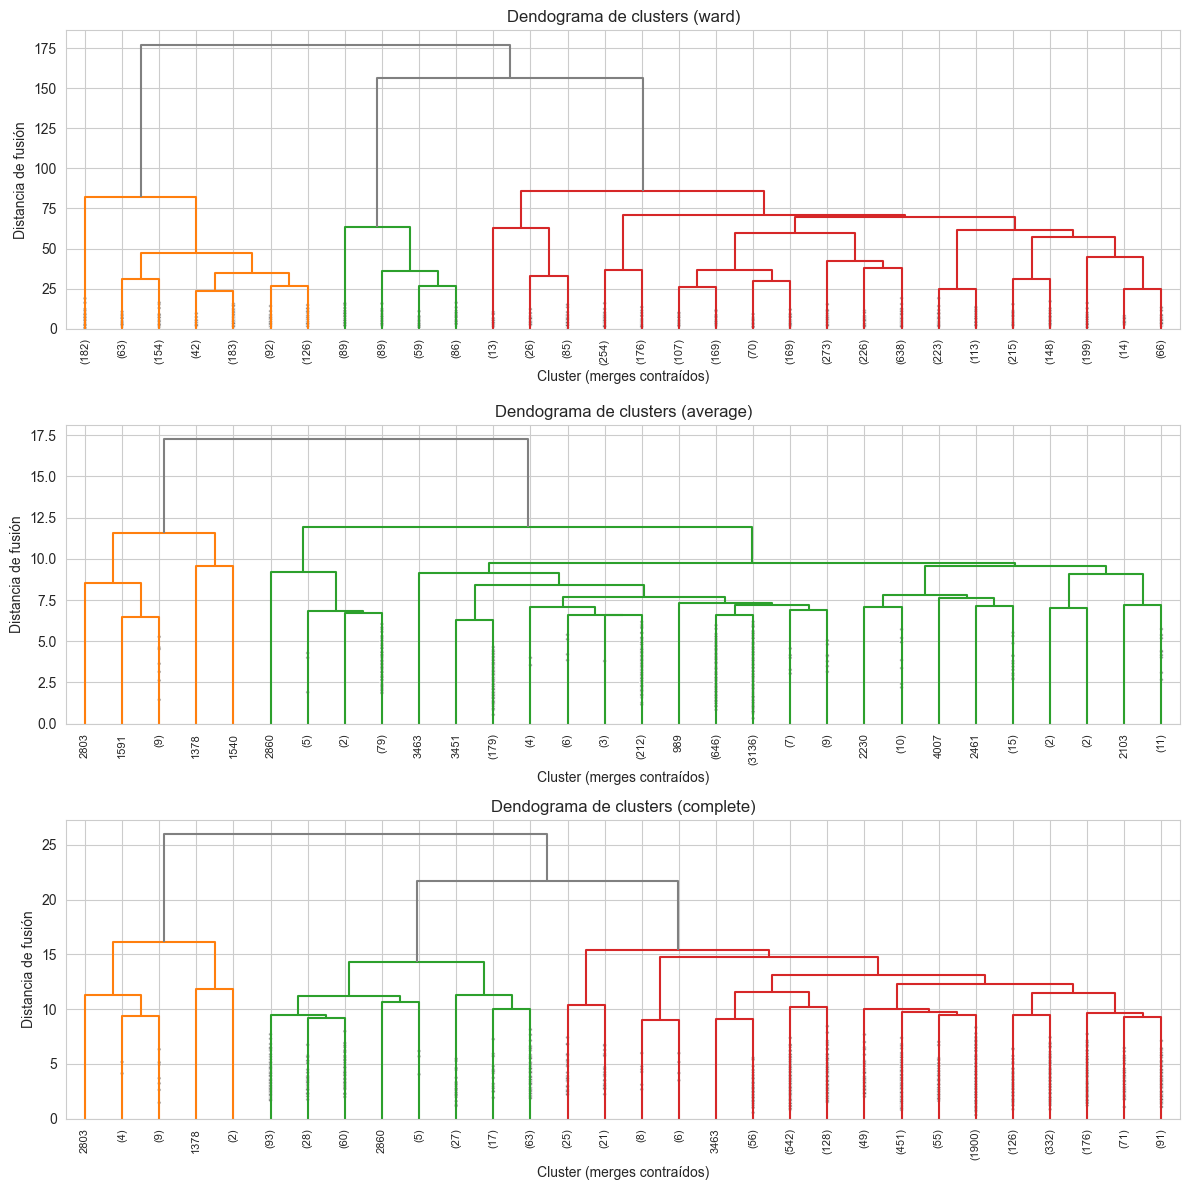

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(12, 12))
for ax, metodo in zip(axes, ("ward", "average", "complete")):
    plot_dendrograma(
        linkages[metodo],
        titulo = f"Dendograma de clusters ({metodo})",
        truncar_a=30,
        ax=ax)
    
plt.tight_layout()
plt.show()

**Lectura de los tres dendrogramas:**

- **Ward:** estructura jerárquica clara, tres ramas grandes que se fusionan a una distancia mucho mayor que el resto.
- **Average:**: un único cluster grande va absorbiendo observaciones aisladas. Esto pasa cuando hay outliers y suele dificultar la elección de k.
- **Complete:** estructura más equilibrada que Average pero los saltos son menos pronunciados que en Ward.

**Elegimos Ward como método principal**

## 6. Selección del número óptimo de clusters

Ordenamos las distancias de fusión y buscamos el mayor salto relativo entre fusiones consecutivas. La idea: si pasar de k a k-1 clusters requiere unir dos grupos que estaban muy alejados, es señal de que esos grupos eran realmente distintos y no debíamos fusionarlos.

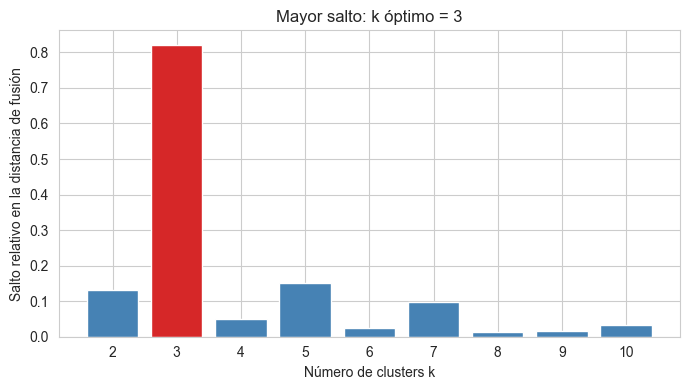

 k  dist_fusion_a_k  dist_siguiente_fusion  salto_absoluto  salto_relativo
 2          156.516                177.112          20.596           0.132
 3           85.962                156.516          70.554           0.821
 4           81.877                 85.962           4.085           0.050
 5           71.126                 81.877          10.751           0.151
 6           69.508                 71.126           1.618           0.023
 7           63.392                 69.508           6.117           0.096
 8           62.555                 63.392           0.836           0.013
 9           61.588                 62.555           0.968           0.016
10           59.640                 61.588           1.947           0.033

-> k óptimo = 3, threshold = 121.24


In [8]:
k_opt, threshold, tabla = seleccionar_k_por_gap(linkages["ward"], k_min=2, k_max=10)

fig, ax = plt.subplots(figsize=(7, 4))
plot_saltos(tabla, k_opt, ax=ax)
plt.tight_layout()
plt.show()

print(tabla.round(3).to_string(index=False))
print(f"\n-> k óptimo = {k_opt}, threshold = {threshold:.2f}")

## 7. Dendrogramas con corte óptimo (Ward, principal)

Mostramos la altura de corte que produce el `k` óptimo.

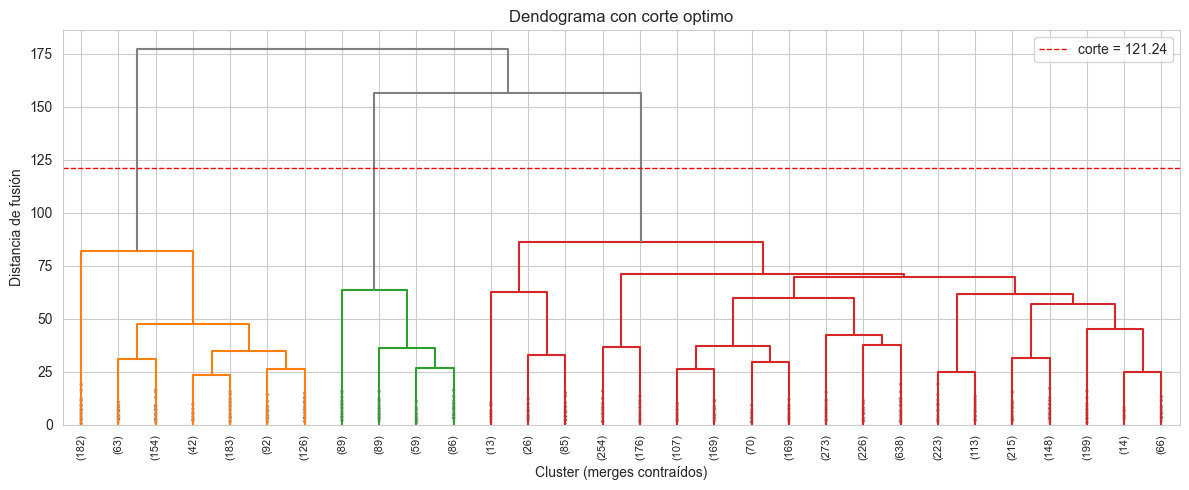

Corte en distancia = 121.24 -> 3 clusters


In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
plot_dendrograma(
    linkages["ward"],
    titulo = f"Dendograma con corte optimo",
    truncar_a=30,
    color_threshold=threshold,
    ax=ax)
plt.tight_layout()
plt.show()

print(f"Corte en distancia = {threshold:.2f} -> {k_opt} clusters")

## 8. Asignación de clusters y validación con silhouette

Asignamos cada estudiante a un cluster según el corte óptimo de Ward, y validamos con el coeficiente de silueta.

In [11]:
labels = ajustar_clusters(linkages["ward"], k=k_opt)

unique, counts = np.unique(labels, return_counts=True)
print(f"Distribución de clusters (Ward, k={k_opt}):")
for u, c in zip(unique, counts):
    print(f"  Cluster {u}: {c:5d} obs ({100*c/len(labels):5.1f}%)")

sil = evaluar_silueta(X, labels, sample_size=2000)
print(f"\nPuntuación de silueta: {sil:.4f}")

Distribución de clusters (Ward, k=3):
  Cluster 1:   842 obs ( 19.4%)
  Cluster 2:   323 obs (  7.4%)
  Cluster 3:  3184 obs ( 73.2%)

Puntuación de silueta: 0.2527


**Interpretación de la silueta:** según lo investigado, valores entre 0.2 y 0.4 son habituales en datasets reales con muchas variables categóricas. Lo importante es que el silhouette sea positivo y los clusters tengan sentido.

## 9. Perfilado interpretativo de los clusters

En este apartado comprobamos el tipo de perfil en cada cluster y su relación con la variable `objetivo`.

In [15]:
perfiles = perfilar_clusters(df, labels)

print("-"*30)
print("TAMAÑOS DE LOS CLUSTERS")
print("-"*30)
print(perfiles["tamaños"])

------------------------------
TAMAÑOS DE LOS CLUSTERS
------------------------------
            n  porcentaje
cluster                  
1         842   19.360773
2         323    7.426995
3        3184   73.212233


In [13]:
print("-"*30)
print("MEDIAS NUMÉRICAS POR CLUSTER")
print("-"*30)
display(perfiles["medias_num"])

------------------------------
MEDIAS NUMÉRICAS POR CLUSTER
------------------------------


,edad_al_matricularse,nota_admision,nota_cualificacion_previa,nota_media_1sem,nota_media_2sem,asignaturas_1sem_aprobadas,asignaturas_2sem_aprobadas
cluster,,,,,,,
1,25.68,126.45,132.44,2.45,0.43,0.53,0.06
2,28.64,127.72,130.91,12.64,12.61,9.33,8.09
3,21.95,126.99,132.85,12.57,12.54,5.16,5.08


In [16]:
print("-"*40)
print("MODA (categoría dominante) POR CLUSTER")
print("-"*40)
display(perfiles["modas_cat"])

----------------------------------------
MODA (categoría dominante) POR CLUSTER
----------------------------------------


,becado,deudor,matricula_al_dia,genero,desplazado,modo_solicitud
cluster,,,,,,
1,no,no,si,hombre,no,acceso_ordinario
2,no,no,si,mujer,no,movilidad_academica
3,no,no,si,mujer,si,acceso_ordinario


In [18]:
print("-"*60)
print("VALIDACIÓN EXTERNA: cluster / objetivo (% por cluster)")
print("-"*60)
display(perfiles["cluster_x_objetivo"])

------------------------------------------------------------
VALIDACIÓN EXTERNA: cluster / objetivo (% por cluster)
------------------------------------------------------------


,%_abandono,%_matriculado,%_graduado
cluster,,,
1,82.2,8.8,9.0
2,31.0,15.5,53.6
3,19.1,20.8,60.1


## 10. Visualización 2D de los clusters

Proyectamos las dos primeras componentes de PCA para ver visualmente la separación.

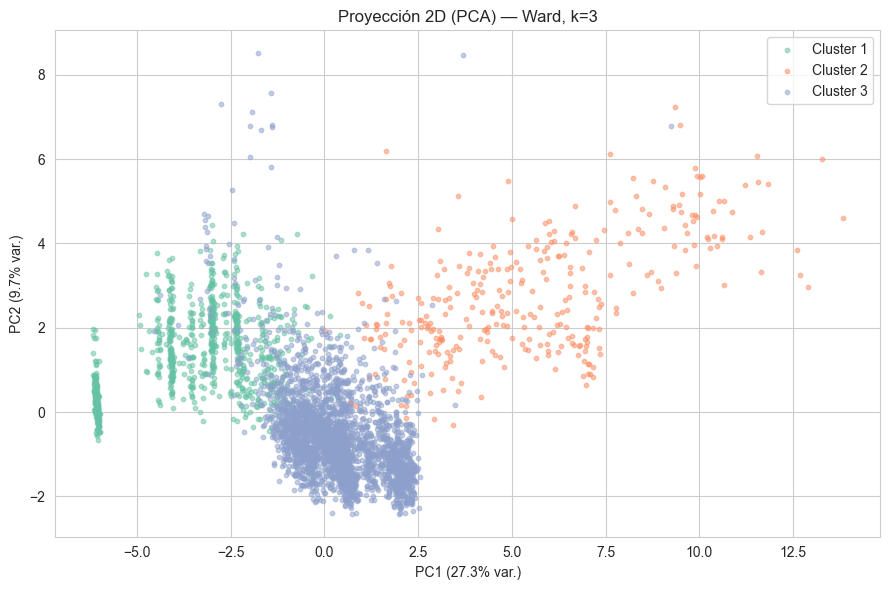

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))
paleta = sns.color_palette("Set2", n_colors=k_opt)
for i, c in enumerate(np.unique(labels)):
    mask = labels == c
    ax.scatter(X[mask, 0], X[mask, 1],
               s=10, alpha=0.5, color=paleta[i], label=f"Cluster {c}")
ax.set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}% var.)")
ax.set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}% var.)")
ax.set_title(f"Proyección 2D (PCA) — Ward, k={k_opt}")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

## 11. Conclusiones de la tarea no supervisada

### Resumen de los perfiles encontrados

(Rellenar tras revisar las tablas anteriores. Plantilla orientativa basada en lo que típicamente sale en este dataset:)

- **Cluster 1 (`19.4% de la población`)**: estudiantes de edad media (alrededor de 25 años), sin beca, con notas 1sem bajas, dominados por la clase **abandono**.
- **Cluster 2 (`7.4% de la población`)**: estudiantes de edad mayor que aquellos en el cluster 1 (28 años de media), con mejores notas pero tampoco becados. La mayor parte de estudiantes en este cluster (50%) termina graduado, seguido de un 30% que termina abandonando.
- **Cluster 3 (`73.2% de la población`)**: El cluster con más estudiantes, compuesto por estudiantes más jovenes que los anteriores y con mejores notas en general. Mayor prevalencia de mujeres en este cluster en comparación con los otros dos clusters (compuestos principalmente por hombres). La etiqueta más prevalente es graduado (60%), con el abandono como la menos prevalente (19%)

### Validación con la variable `objetivo`

La tabla cluster / objetivo muestra que **los clusters capturan la variable objetivo** parcialmente, sin haberla visto. Cada cluster tiene una distribución claramente sesgada hacia una de las tres clases. Esto sugiere que los perfiles encontrados son relevantes y no aleatorios.

### Limitaciones

1. **Distancia euclídea entre OneHot**: no es la métrica ideal para variables categóricas.
2. **PCA y la interpretabilidad de las componentes**: aunque ayuda al algoritmo, los componentes PCA no son interpretables. El perfilado se hace sobre las variables originales para evitar esto.
3. **El criterio del salto**: distintos linkages pueden sugerir distintos k. Hemos elegido Ward como referencia, pero la elección no es única.
4. **Correlación no implica causalidad**: que un cluster se asocie con abandono no significa que las características que lo definen causen el abandono. Solo los identifican.

### Aplicación práctica

Si la institución universitaria pudiera identificar a un estudiante en el cluster de mayor riesgo al final del primer semestre, podría dirigir intervenciones específicas (tutorías, apoyo financiero, asesoramiento académico) hacia ese subgrupo, optimizando el uso de recursos limitados.